# Explore HDF5 Dataset

This notebook inspects the contents of the `cartpole_random.hdf5` dataset collected from the pick & place tutorial environment.

In [1]:
import h5py
import numpy as np
import os

## Load the dataset

In [3]:
dataset_path = os.path.join("..", "datasets", "mirror.hdf5_failed.hdf5")
print(f"Dataset path: {os.path.abspath(dataset_path)}")
print(f"File exists: {os.path.exists(dataset_path)}")
print(f"File size: {os.path.getsize(dataset_path) / 1e6:.2f} MB")

Dataset path: /storage/homefs/an23d073/IsaacLab-Arena/master-thesis/era_bench/datasets/mirror.hdf5_failed.hdf5
File exists: True
File size: 31.26 MB


## Inspect the file structure

In [ ]:
with h5py.File(dataset_path, "r") as f:
    print("=== Top-level keys ===")
    print(list(f.keys()))
    print()

    print("=== Full structure ===")
    def print_structure(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"  [Dataset] {name:50s} shape={obj.shape}, dtype={obj.dtype}")
        elif isinstance(obj, h5py.Group):
            print(f"  [Group]   {name}")

    f.visititems(print_structure)

## Inspect top-level attributes

In [ ]:
with h5py.File(dataset_path, "r") as f:
    print("=== File-level attributes ===")
    for key, val in f.attrs.items():
        print(f"  {key}: {val}")

## Inspect individual episodes / groups

In [ ]:
with h5py.File(dataset_path, "r") as f:
    # Look at the first group in detail
    top_keys = list(f.keys())
    print(f"Number of top-level entries: {len(top_keys)}")
    print(f"First few keys: {top_keys[:5]}")
    print()

    # Inspect first entry
    first_key = top_keys[0]
    entry = f[first_key]
    print(f"=== Inspecting '{first_key}' ===")
    if isinstance(entry, h5py.Group):
        print(f"  Sub-keys: {list(entry.keys())}")
        print(f"  Attributes: {dict(entry.attrs)}")
        for sub_key in entry.keys():
            sub = entry[sub_key]
            if isinstance(sub, h5py.Dataset):
                print(f"    {sub_key}: shape={sub.shape}, dtype={sub.dtype}")
            elif isinstance(sub, h5py.Group):
                print(f"    {sub_key}/ (group with keys: {list(sub.keys())})")
    elif isinstance(entry, h5py.Dataset):
        print(f"  shape={entry.shape}, dtype={entry.dtype}")
        print(f"  First few values: {entry[:5]}")

## Sample data from datasets

In [ ]:
with h5py.File(dataset_path, "r") as f:
    # Collect all datasets and print sample values
    datasets = []
    def collect_datasets(name, obj):
        if isinstance(obj, h5py.Dataset):
            datasets.append(name)
    f.visititems(collect_datasets)

    print(f"Total number of datasets: {len(datasets)}")
    print()

    # Show sample from first few datasets
    for ds_name in datasets[:10]:
        ds = f[ds_name]
        print(f"--- {ds_name} ---")
        print(f"    shape: {ds.shape}, dtype: {ds.dtype}")
        if ds.size > 0:
            sample = ds[0] if len(ds.shape) > 0 else ds[()]
            print(f"    first entry: {sample}")
        print()

## Summary statistics

In [ ]:
with h5py.File(dataset_path, "r") as f:
    # Collect all dataset names
    datasets = []
    def collect_datasets(name, obj):
        if isinstance(obj, h5py.Dataset):
            datasets.append(name)
    f.visititems(collect_datasets)

    # Print min/max/mean for numeric datasets
    for ds_name in datasets[:10]:
        ds = f[ds_name]
        if np.issubdtype(ds.dtype, np.number) and ds.size > 0:
            data = ds[:]
            print(f"{ds_name}:")
            print(f"    min={data.min():.4f}, max={data.max():.4f}, mean={data.mean():.4f}, std={data.std():.4f}")
            print()

## Play video from dataset

In [22]:
import base64
from IPython.display import HTML, display

# Choose which demo to play
demo_index = 3
video_key = f"data/demo_{demo_index}/video"

with h5py.File(dataset_path, "r") as f:
    if video_key in f:
        video_data = f[video_key]
        print(f"Video dataset: {video_key}")
        print(f"  shape: {video_data.shape}, dtype: {video_data.dtype}")

        raw = video_data[()]

        # Handle various storage formats
        if isinstance(raw, (bytes, np.void)):
            video_bytes = bytes(raw)
        elif isinstance(raw, np.ndarray):
            if raw.dtype == np.uint8:
                # Flatten any extra dimensions — stored as (1, N) or (N,)
                video_bytes = raw.flatten().tobytes()
            elif raw.dtype == object:
                inner = raw.item() if raw.ndim == 0 else raw.flat[0]
                video_bytes = bytes(inner) if isinstance(inner, (bytes, np.void)) else np.asarray(inner).tobytes()
            else:
                print(f"  Unexpected dtype: {raw.dtype}, shape: {raw.shape}")
                video_bytes = None
        else:
            print(f"  Unexpected type: {type(raw)}")
            video_bytes = None

        if video_bytes and len(video_bytes) > 0:
            print(f"  Video size: {len(video_bytes) / 1024:.1f} KB")
            b64 = base64.b64encode(video_bytes).decode("utf-8")
            html = f'''
            <video controls autoplay loop style="max-width: 640px;">
                <source src="data:video/mp4;base64,{b64}" type="video/mp4">
            </video>
            '''
            display(HTML(html))
        elif video_bytes is not None:
            print("  Video dataset is empty (0 bytes) — episode may have had no frames.")
    else:
        print(f"Key '{video_key}' not found in dataset.")
        print("\nAvailable keys under 'data/':")
        if "data" in f:
            for k in list(f["data"].keys())[:5]:
                print(f"  data/{k}/ -> {list(f[f'data/{k}'].keys())}")

Video dataset: data/demo_3/video
  shape: (1, 155599), dtype: uint8
  Video size: 152.0 KB


## Inspect frames from `data/demo_0/obs/table_cam/rgb`

This cell loads RGB frames and plots a sampled subset so you can quickly verify image quality and ordering.

Dataset shape: (100, 384, 384, 3), dtype: uint8


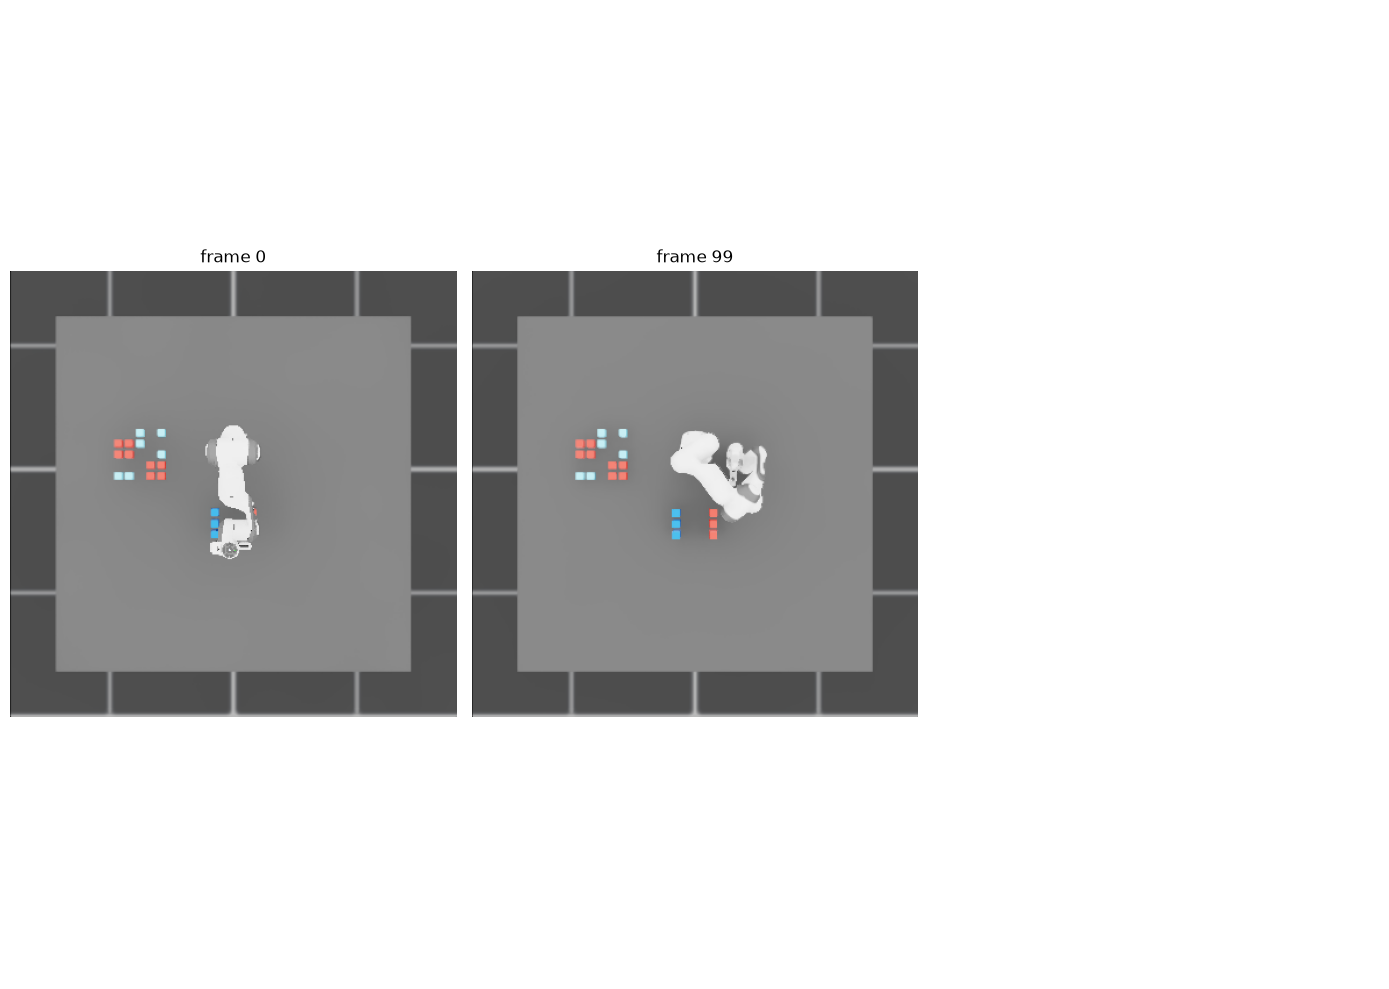

In [21]:
import matplotlib.pyplot as plt

# Edit these frame indices to inspect different frames
frame_indices = [0, 99]#, 250, 335, 500, 750, 900, 1200]
demo = 1
with h5py.File(dataset_path, "r") as f:
    rgb = f[f"data/demo_{demo}/obs/origin_top_cam"]
    print(f"Dataset shape: {rgb.shape}, dtype: {rgb.dtype}")
    
    frames = rgb[()]
    
    cols = 3
    rows = int(np.ceil(len(frame_indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 10))
    axes = np.array(axes).reshape(-1)
    
    for ax_i, idx in enumerate(frame_indices):
        axes[ax_i].imshow(frames[idx])
        axes[ax_i].set_title(f"frame {idx}", fontsize=12)
        axes[ax_i].axis("off")
    
    for ax_i in range(len(frame_indices), len(axes)):
        axes[ax_i].axis("off")
    
    plt.tight_layout()
    plt.show()
